# Inland Excess Water (IEW) Monitoring — Pretrained Terrain-Aware UPerNet (PT-UPerNet)

**Notebook 12. The second new architecture. It is deliberately different from notebook 11.**

| | Notebook 11 (Temporal-Radar Former) | **Notebook 12 (PT-UPerNet)** |
|---|---|---|
| Core bet | *Time*: earlier acquisitions of the same site | ***Prior knowledge + terrain***: networks pre-trained on millions of Sentinel images, plus an elevation model |
| Weights at start | Random, then our own self-supervised pre-training on 14 scenes | **SSL4EO-S12 pre-trained ResNet-50s** (MoCo self-supervised on about 250k locations × 4 seasons of Sentinel-1 and Sentinel-2 worldwide) |
| Dates per sample | Target + up to 3 earlier | Target date only |
| Extra data | None | **Copernicus 30 m elevation model (free)** → relative elevation, slope, and depression indices at 3 scales |
| Encoder | Per-pixel temporal transformer → ConvNeXt | Two full ResNet-50 encoders (optical, radar) + a light terrain/index encoder, fused at every scale |
| Decoder | FPN | **UPerNet** (pyramid pooling + FPN), the standard decoder for pre-trained backbones |

### Why this should help the hard classes

- **Pre-training.** 14 labelled scenes are not enough to learn what Sentinel-2 and Sentinel-1 *look like* from scratch. SSL4EO-S12 encoders already know vegetation, soil, water, moisture texture and seasonal appearance. Fine-tuning only has to learn the IEW-specific boundaries. In remote sensing this is usually the single biggest gain when labels are scarce.
- **Terrain.** Inland excess water is a **topographic** phenomenon: water collects in shallow depressions of flat plains, and severity follows how deep and wide the depression is. None of notebooks 01–11 has elevation data. This notebook builds, per pixel:
  - relative elevation (height above the site median);
  - slope;
  - **topographic position index (TPI)** at 150 m, 500 m and 1.5 km. TPI is the pixel's height minus the mean height around it, so negative values mean the pixel is in a depression.
- **Same structured output as notebook 11:** flat 6-class head + coarse 4-class head + **ordinal severity head** for soil (slight < moderate < serious), blended and calibrated on held-out training scenes.

### Architecture

```
 S2 (11 bands, reflectance)       ──► ResNet-50, SSL4EO-S12 S2 MoCo (first conv adapted 13 → 11 bands)
                                        1/2:64   1/4:256   1/8:512   1/16:1024   1/32:2048
 S1 (VV, VH, standardised dB)     ──► ResNet-50, SSL4EO-S12 S1 MoCo
                                        1/2:64   1/4:256   1/8:512   1/16:1024   1/32:2048
 Aux (15 ch: 6 spectral indices, cloud score, S2 valid, VV/VH ratio, S1 valid,
      5 terrain features)          ──► light CNN encoder
                                                 1/4:64    1/8:128   1/16:192    1/32:256

 per scale:  concat(S2, S1, Aux) → 1×1 conv → 256 ch → channel gate (squeeze-excitation)
             = cross-modal fusion, learned separately at each of the 4 scales

 UPerNet:    pyramid pooling (1,2,3,6) on the 1/32 map → FPN top-down over all 4 scales
             → concat → 256 ch @ 1/4                          ──► aux head (6), deep supervision
                                                  1/16 map    ──► aux head (6), deep supervision
 refine:     ↑2 + S2/S1 stem features (1/2)       → 128 ch @ 1/2
             ↑2 + full-res branch (1×1 spectral MLP ‖ 3×3 conv on all inputs) → 64 ch @ full res

 heads:      main (6)   coarse (4)   ordinal (2: P(≥moderate), P(serious | ≥moderate))
```

About 60 M parameters, about 47 M of them pre-trained. The exact count is printed in §4.

### Training recipe

| Item | Setting | Why |
|---|---|---|
| Phase 1 (`FREEZE_EPOCHS = 3`) | Pre-trained encoders frozen, only fusion/decoder/heads train | New layers start random. Big early gradients would otherwise damage the pre-trained features. |
| Phase 2 | Everything trains; pre-trained encoders at `BACKBONE_LR = 1e-4`, new layers at `MAX_LR = 1e-3` | Standard fine-tuning with discriminative learning rates |
| BatchNorm in the pre-trained encoders | Statistics frozen throughout (scale/shift still learn) | Batch size 8 is too small to re-estimate BN statistics reliably |
| Loss | Ordinal-smoothed weighted CE + Dice + 2 deep-supervision heads + coarse CE + ordinal BCE | Same structure-aware loss as notebook 11 |
| Sampling | Class-aware sampler from notebook 10, 256-px patches | Rare soil classes are oversampled |
| Weights for evaluation | EMA (0.999) | Smooths epoch-to-epoch jumps |
| Inference | 640-px windows → 512-px centres, D4 test-time augmentation, head blend + logit bias fitted on held-out training scenes | Same protocol as notebook 11, so the two are directly comparable |

### Honest expectations

Notebook 10 reached about 98 F1 on water and not-affected, and 60–71 F1 on the soil-severity and vegetation classes (test set, calibrated). The goal here is a clear gain on the hard classes. **90+ F1 on every class is not guaranteed**, because the serious/moderate/slight boundaries in the ground truth are themselves fuzzy. Report what you get in §14. The ablation in §9 measures how much terrain and radar each contribute.

### How to run (on a GPU machine with internet)

1. **Python packages:** `torch>=2.1` (CUDA build), `torchgeo>=0.6` (installs `timm`), `rasterio`, `numpy`, `pyyaml`, `matplotlib`. For example: `pip install torchgeo rasterio pyyaml matplotlib`.
2. **Dataset path:** edit `dataset_root` in `configs/data.yaml`.
3. **Internet is needed once:**
   - the SSL4EO-S12 weights (about 100 MB each) download automatically to the torch hub cache;
   - Copernicus DEM tiles download from the public AWS bucket into `outputs/dem/raw/`.

   **Without internet for the DEM:** download the Copernicus GLO-30 tiles covering the two sites by hand (any GeoTIFF DEM in any projection works) and put them in `outputs/dem/raw/`. The notebook then uses them. Or set `USE_DEM = False`, which sets the terrain channels to zero.
4. **First do a dry run:** set `QUICK_TEST = True` and run all cells. If everything finishes, set it back to `False` and run again from a fresh kernel.
5. **GPU memory:** the defaults (`PATCH=256`, `BATCH_SIZE=8`, mixed precision) fit in about 8–12 GB. If you run out of memory, set `BATCH_SIZE = 4`, or `PATCH = 192` (must stay divisible by 32).
6. **Interruptions:** a checkpoint is saved every epoch, and training resumes automatically.

### Outputs

- `outputs/dem/<site>_*.npy`: terrain features aligned to each site's pixel grid (cached)
- `outputs/checkpoints/ptuper_best.pt`: best EMA weights
- `outputs/checkpoints/ptuper_last.pt`: resumable training state
- `outputs/checkpoints/ptuper_calibration.json`: head-blend weight + per-class logit bias
- `outputs/ptuper_results.json`: test metrics, per-scene scores, ablation

## 1. Imports and configuration

In [32]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
os.environ["PROJ_NETWORK"] = "OFF"

import math
import random
import time
import urllib.request
from pathlib import Path

import numpy as np
import yaml
import rasterio

import copy
import json
import math
import time
import urllib.request
from pathlib import Path

import numpy as np
import yaml
import rasterio
from rasterio.windows import Window
from rasterio.warp import reproject, Resampling, transform_bounds
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

QUICK_TEST = False          # True = tiny dry run of the whole notebook (writes *_quicktest* checkpoints only)

SEED          = 0
PATCH         = 256         # training patch size, must be divisible by 32
GRID_STRIDE   = 64
BATCH_SIZE    = 16
NUM_WORKERS   = 0           # keep 0 on Windows + Jupyter; 4 is fine on Linux
USE_AMP       = True
RESUME        = True

PRETRAINED    = True        # SSL4EO-S12 weights via torchgeo (needs internet once)
USE_DEM       = True        # Copernicus 30 m DEM terrain features (needs internet once, or manual tiles)

EPOCHS            = 20
FREEZE_EPOCHS     = 2       # pre-trained encoders frozen for the first epochs
SAMPLES_PER_EPOCH = 1000
VAL_PATCHES       = 150
MAX_LR            = 1e-3    # new layers (fusion, decoder, heads, aux encoder)
BACKBONE_LR       = 1e-4    # pre-trained ResNet-50s
WEIGHT_DECAY      = 0.01
WARMUP_FRAC       = 0.05
EMA_DECAY         = 0.999
ORDINAL_SMOOTH    = 0.10
GAIN_JITTER       = 0.05    # training: per-band multiplicative S2 gain noise

TILE, MARGIN = 512, 64
TTA          = "flip"         # "none" | "flip" | "d4"

VAL_SCENES  = ["BNPI_20230208", "KNPI_20220310"]          # same as notebooks 10 and 11
CLASS_SHARE = {0: 0.05, 1: 0.20, 2: 0.20, 3: 0.10, 4: 0.10}

MAX_TILES = None
if QUICK_TEST:
    EPOCHS, FREEZE_EPOCHS, SAMPLES_PER_EPOCH, VAL_PATCHES = 2, 1, 32, 16
    TTA, MAX_TILES = "none", 2

TAG       = "ptuper" + ("_quicktest" if QUICK_TEST else "")
CKPT_DIR  = Path("outputs/checkpoints")
CKPT_DIR.mkdir(parents=True, exist_ok=True)
BEST_PATH = CKPT_DIR / f"{TAG}_best.pt"
LAST_PATH = CKPT_DIR / f"{TAG}_last.pt"
CAL_PATH  = CKPT_DIR / f"{TAG}_calibration.json"
RESULTS_PATH = Path("outputs") / f"{TAG}_results.json"
DEM_DIR = Path("outputs/dem")
DEM_RAW = DEM_DIR / "raw"
DEM_RAW.mkdir(parents=True, exist_ok=True)

assert PATCH % 32 == 0 and (TILE + 2 * MARGIN) % 32 == 0, "sizes must be divisible by 32"

torch.manual_seed(SEED)
np.random.seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP_ON = USE_AMP and device.type == "cuda"
AMP_DTYPE = torch.bfloat16 if (AMP_ON and torch.cuda.is_bf16_supported()) else torch.float16
if device.type == "cuda":
    torch.backends.cudnn.benchmark = True
    print(f"GPU: {torch.cuda.get_device_name(0)} | "
          f"{torch.cuda.get_device_properties(0).total_memory / 2**30:.1f} GB")
else:
    print("WARNING: no CUDA GPU found - this notebook is meant for a GPU. Use QUICK_TEST only on CPU.")
print(f"PyTorch {torch.__version__} | device {device} | AMP {AMP_ON} ({AMP_DTYPE if AMP_ON else '-'})")


def autocast():
    return torch.autocast(device_type=device.type, dtype=AMP_DTYPE, enabled=AMP_ON)


def make_scaler():
    enabled = AMP_ON and AMP_DTYPE == torch.float16
    try:
        return torch.amp.GradScaler("cuda", enabled=enabled)
    except (AttributeError, TypeError):
        return torch.cuda.amp.GradScaler(enabled=enabled)

GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU | 6.0 GB
PyTorch 2.6.0+cu124 | device cuda | AMP True (torch.bfloat16)


## 2. Data: scenes and per-pixel inputs

Each sample contains three inputs plus the label:

- `s2`: 11 Sentinel-2 bands as **reflectance (DN / 10000)**. This is the scaling the SSL4EO-S12 optical encoder was pre-trained with. No-data pixels are 0.
- `s1`: VV and VH, standardised with the dataset's statistics.
- `aux`: 15 channels, all zero where invalid:
  - the 6 spectral indices from notebook 10;
  - a cloud/haze score;
  - the S2 valid flag;
  - the standardised VV/VH ratio;
  - the S1 valid flag;
  - **5 terrain features** (§3).

The class mapping (`raw 2..7 → 0..5`, everything else ignored) is the same as in notebooks 10 and 11.

In [33]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
os.environ["PROJ_NETWORK"] = "OFF"

with open("configs/data.yaml", "r") as f:
    config = yaml.safe_load(f)

dataset_root = Path(config["dataset_root"])
LOCAL_ROOT = Path("dataset")
if not dataset_root.exists() and LOCAL_ROOT.exists():
    dataset_root = LOCAL_ROOT
assert dataset_root.exists(), f"Dataset not found at {dataset_root} - edit dataset_root in configs/data.yaml"
print(f"Dataset root: {dataset_root}")

IGNORE = 255
NUM_CLASSES = 6
CLASS_NAMES = [
    "Open surface water (raw 2)",
    "Soil seriously affected (raw 3)",
    "Soil moderately affected (raw 4)",
    "Soil slightly affected (raw 5)",
    "Vegetation affected (raw 6)",
    "Not affected (raw 7)",
]
GT_LUT = np.full(256, IGNORE, dtype=np.uint8)
for raw, cls in {2: 0, 3: 1, 4: 2, 5: 3, 6: 4, 7: 5}.items():
    GT_LUT[raw] = cls

# Band order: B01 B02 B03 B04 B05 B06 B07 B08 B8A B11 B12
S2_MEAN = np.array([0.0436, 0.0557, 0.0723, 0.0838, 0.1151, 0.1598,
                    0.1800, 0.1974, 0.2004, 0.2233, 0.1706], dtype=np.float32)
S2_STD  = np.array([0.0182, 0.0233, 0.0272, 0.0340, 0.0380, 0.0598,
                    0.0686, 0.0751, 0.0728, 0.0674, 0.0606], dtype=np.float32)
S1_MEAN = np.array([-21.6081, -13.6686, -8.0403], dtype=np.float32)
S1_STD  = np.array([3.4706, 3.0644, 2.5309], dtype=np.float32)

N_DEM   = 5
AUX_CH  = 6 + 1 + 1 + 1 + 1 + N_DEM     # indices, cloud, S2 valid, VV/VH ratio, S1 valid, terrain
FULL_CH = 11 + 2 + AUX_CH               # inputs of the full-resolution refinement branch


def make_inputs(s2_raw: np.ndarray, s1_raw: np.ndarray, dem):
    """Raw window arrays -> s2 (11,h,w) reflectance, s1 (2,h,w) standardised, aux (15,h,w)."""
    s2 = s2_raw.astype(np.float32)
    v2 = np.isfinite(s2).all(0)
    s2 = np.nan_to_num(s2, nan=0.0, posinf=0.0, neginf=0.0) / 10000.0
    v2 &= s2.sum(0) > 0
    s2 = np.clip(s2, 0.0, 2.0) * v2[None]

    eps = 1e-6
    blue, green, red, nir, nir_n, swir1, swir2 = s2[1], s2[2], s2[3], s2[7], s2[8], s2[9], s2[10]
    indices = np.stack([
        (nir - red) / (nir + red + eps),            # NDVI
        (nir_n - swir1) / (nir_n + swir1 + eps),    # NDMI
        (green - nir) / (green + nir + eps),        # NDWI
        (green - swir1) / (green + swir1 + eps),    # MNDWI
        (swir1 - red) / (swir1 + red + eps),        # SWIR1-RED soil-moisture index
        (swir1 - swir2) / (swir1 + swir2 + eps),    # SWIR ratio
    ]) * 2.0
    cloud = np.clip((np.minimum(blue, red) - 0.10) / 0.20, 0.0, 1.0)

    s1 = s1_raw.astype(np.float32)
    v1 = np.isfinite(s1).all(0)
    s1 = np.nan_to_num(s1, nan=0.0, posinf=0.0, neginf=0.0)
    v1 &= np.abs(s1[0]) > 1e-6
    s1n = np.clip((s1 - S1_MEAN[:, None, None]) / S1_STD[:, None, None], -6.0, 6.0) * v1[None]

    h, w = s2.shape[1:]
    terrain = dem.astype(np.float32) if dem is not None else np.zeros((N_DEM, h, w), dtype=np.float32)
    f2, f1 = v2.astype(np.float32), v1.astype(np.float32)
    aux = np.concatenate([indices * f2[None], (cloud * f2)[None], f2[None], s1n[2:3], f1[None], terrain], axis=0)
    aux = np.clip(np.nan_to_num(aux, nan=0.0, posinf=6.0, neginf=-6.0), -6.0, 6.0)
    return s2.astype(np.float32), s1n[:2].astype(np.float32), aux.astype(np.float32)


class Scene:
    """One acquisition. S2/S1 read by window; GT and terrain held in RAM."""

    def __init__(self, split: str, split_dir: Path, filename: str):
        self.name = Path(filename).stem
        self.split = split
        self.site = self.name.split("_")[0]
        self.s2_path = split_dir / "S2" / filename
        self.s1_path = split_dir / "S1" / filename
        self.gt_path = split_dir / "GT" / filename
        for p in (self.s1_path, self.gt_path):
            if not p.exists():
                raise FileNotFoundError(f"Missing file: {p}")
        with rasterio.open(self.s2_path) as src:
            self.H, self.W = src.height, src.width
            self.transform, self.crs, self.bounds = src.transform, src.crs, src.bounds
        self.dem = None              # (5,H,W) float16, filled in §3
        self._gt = None
        self._s2 = None
        self._s1 = None

    @property
    def gt(self) -> np.ndarray:
        if self._gt is None:
            with rasterio.open(self.gt_path) as src:
                raw = np.nan_to_num(src.read(1), nan=0.0)
            gt = GT_LUT[np.clip(raw, 0, 255).astype(np.uint8)]
            assert gt.shape == (self.H, self.W), f"GT size mismatch in {self.name}"
            self._gt = gt
        return self._gt

    # def read(self, r: int, c: int, h: int, w: int):
    #     if self._s2 is None:
    #         self._s2 = rasterio.open(self.s2_path)
    #         self._s1 = rasterio.open(self.s1_path)
    #     win = Window(c, r, w, h)
    #     dem = self.dem[:, r:r + h, c:c + w] if self.dem is not None else None
    #     return self._s2.read(window=win), self._s1.read(window=win), dem

    def read(self, r: int, c: int, h: int, w: int):
        if self._s2 is None:
            with rasterio.open(self.s2_path) as src:
                self._s2_data = src.read()
            with rasterio.open(self.s1_path) as src:
                self._s1_data = src.read()
            self._s2 = True
        dem = self.dem[:, r:r + h, c:c + w] if self.dem is not None else None
        return self._s2_data[:, r:r + h, c:c + w], self._s1_data[:, r:r + h, c:c + w], dem


    def __getstate__(self):
        state = self.__dict__.copy()
        state["_s2"] = state["_s1"] = None
        return state


def load_split(split: str):
    split_dir = dataset_root / "tifs" / split
    if not split_dir.exists():
        split_dir = dataset_root / split
    files = sorted(p.name for p in (split_dir / "S2").glob("*.tif"))
    if not files:
        raise FileNotFoundError(f"No .tif files under {split_dir / 'S2'}")
    return [Scene(split, split_dir, fn) for fn in files]


all_train = load_split("Train")
all_test  = load_split("Test")
missing = set(VAL_SCENES) - {s.name for s in all_train}
assert not missing, f"VAL_SCENES not found in Train split: {missing}"
train_scenes = [s for s in all_train if s.name not in VAL_SCENES]
val_scenes   = [s for s in all_train if s.name in VAL_SCENES]
print(f"Train scenes: {len(train_scenes)} | held-out val scenes: {[s.name for s in val_scenes]} | test scenes: {len(all_test)}")
print(f"CRS of first scene: {all_train[0].crs} | pixel size: {abs(all_train[0].transform.a):.1f} m")

Dataset root: dataset
Train scenes: 12 | held-out val scenes: ['BNPI_20230208', 'KNPI_20220310'] | test scenes: 9
CRS of first scene: EPSG:23700 | pixel size: 10.0 m


## 3. Terrain features from the Copernicus 30 m DEM

1. **Download.** For each site, convert the scene bounds to latitude/longitude and fetch the 1°×1° Copernicus GLO-30 tiles covering it from the public AWS bucket (`copernicus-dem-30m`, no account needed). Tiles already in `outputs/dem/raw/` are reused, so you can also drop tiles there by hand.
2. **Align.** Reproject (bilinear) every overlapping tile onto the scene's exact 10 m pixel grid.
3. **Features (5 channels).** Each is scaled and clipped to ±6:
   - relative elevation: height − site median, divided by 10 m;
   - slope in degrees, divided by 2;
   - **TPI at 150 m, 500 m and 1.5 km**: height − mean height in a square window of that radius, divided by 2 m. Negative TPI means the pixel sits in a depression, where excess water collects.
4. Results are cached once per site grid as `.npy` files. All dates of a site share one grid, so the DEM is computed only once per site.

The DEM is static external data, so it causes no label or test leakage. Expect it to matter mostly for the soil-severity classes. §9 measures it.

Terrain features ready for 2 site grid(s): ['BNPI_3600x5400_723000_267000', 'KNPI_2400x4800_639000_174000']


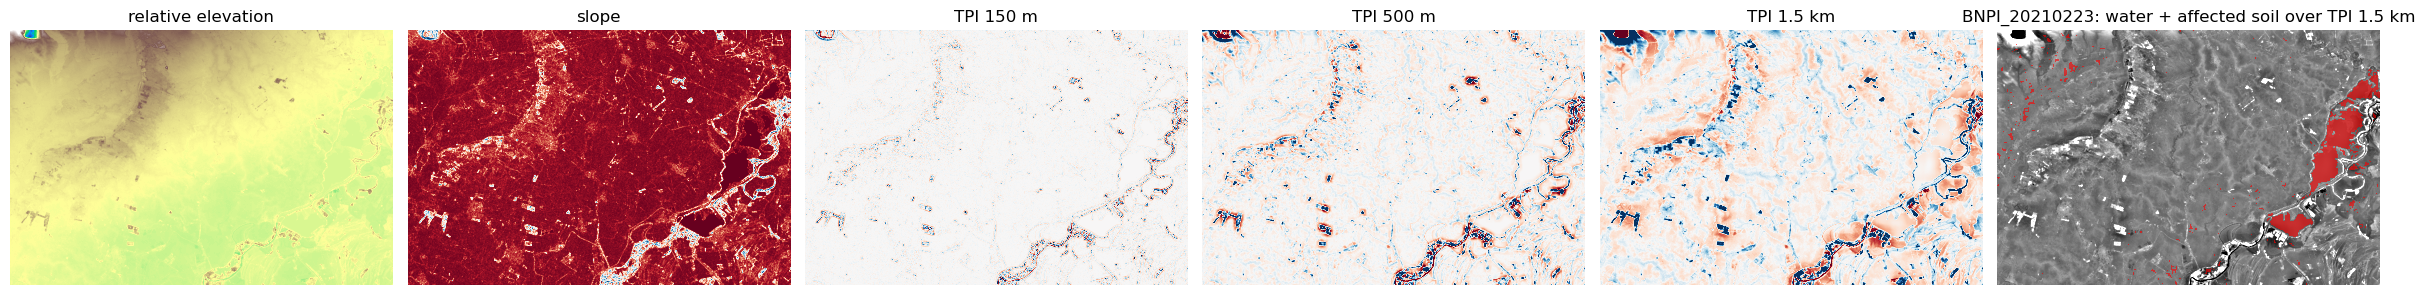

In [34]:
def cop_dem_tile(lat: int, lon: int):
    ns, ew = ("N" if lat >= 0 else "S"), ("E" if lon >= 0 else "W")
    name = f"Copernicus_DSM_COG_10_{ns}{abs(lat):02d}_00_{ew}{abs(lon):03d}_00_DEM"
    return name, f"https://copernicus-dem-30m.s3.amazonaws.com/{name}/{name}.tif"


def ensure_dem_tiles(sc: Scene):
    w, s, e, n = transform_bounds(sc.crs, "EPSG:4326", *sc.bounds, densify_pts=21)
    for lat in range(math.floor(s), math.floor(n) + 1):
        for lon in range(math.floor(w), math.floor(e) + 1):
            name, url = cop_dem_tile(lat, lon)
            path = DEM_RAW / f"{name}.tif"
            if path.exists():
                continue
            tmp = path.with_suffix(".part")
            try:
                print(f"  downloading {name} ...")
                urllib.request.urlretrieve(url, tmp)
                tmp.rename(path)
            except Exception as ex:
                if tmp.exists():
                    tmp.unlink()
                print(f"  WARNING: could not download {name} ({ex}). Put the tile in {DEM_RAW} manually if needed.")


def dem_on_grid(sc: Scene) -> np.ndarray:
    dst = np.full((sc.H, sc.W), np.nan, dtype=np.float32)
    for tif in sorted(DEM_RAW.glob("*.tif")):
        with rasterio.open(tif) as src:
            l, b, r, t = transform_bounds(src.crs, sc.crs, *src.bounds, densify_pts=21)
            if r <= sc.bounds.left or l >= sc.bounds.right or t <= sc.bounds.bottom or b >= sc.bounds.top:
                continue
            tmp = np.full_like(dst, np.nan)
            reproject(source=rasterio.band(src, 1), destination=tmp,
                      src_transform=src.transform, src_crs=src.crs, src_nodata=src.nodata,
                      dst_transform=sc.transform, dst_crs=sc.crs, dst_nodata=np.nan,
                      resampling=Resampling.bilinear)
            fill = np.isnan(dst) & np.isfinite(tmp)
            dst[fill] = tmp[fill]
    return dst


def box_mean(a: np.ndarray, r: int) -> np.ndarray:
    """Mean over a (2r+1)x(2r+1) window, reflect-padded at the borders (integral image)."""
    k = 2 * r + 1
    p = np.pad(a.astype(np.float64), r, mode="reflect")
    I = np.zeros((p.shape[0] + 1, p.shape[1] + 1), dtype=np.float64)
    I[1:, 1:] = p.cumsum(0).cumsum(1)
    return ((I[k:, k:] - I[:-k, k:] - I[k:, :-k] + I[:-k, :-k]) / (k * k)).astype(np.float32)


def dem_features(dem: np.ndarray, pixel_m: float) -> np.ndarray:
    valid = np.isfinite(dem)
    if valid.mean() < 0.5:
        raise RuntimeError(f"DEM covers only {100 * valid.mean():.0f}% of the scene - check tiles in {DEM_RAW}")
    med = float(np.nanmedian(dem))
    dem = np.where(valid, dem, med).astype(np.float32)
    gy, gx = np.gradient(dem, pixel_m)
    slope = np.degrees(np.arctan(np.hypot(gx, gy)))
    radii = [max(1, int(round(m / pixel_m))) for m in (150, 500, 1500)]
    feats = [(dem - med) / 10.0, slope / 2.0] + [(dem - box_mean(dem, r)) / 2.0 for r in radii]
    return np.clip(np.stack(feats), -6.0, 6.0).astype(np.float16)


def grid_key(sc: Scene) -> str:
    return f"{sc.site}_{sc.H}x{sc.W}_{int(round(sc.transform.c))}_{int(round(sc.transform.f))}"


if USE_DEM:
    cache = {}
    for sc in all_train + all_test:
        key = grid_key(sc)
        if key not in cache:
            path = DEM_DIR / f"{key}.npy"
            if path.exists():
                cache[key] = np.load(path)
            else:
                t0 = time.time()
                print(f"Terrain features for {key}:")
                ensure_dem_tiles(sc)
                cache[key] = dem_features(dem_on_grid(sc), abs(sc.transform.a))
                np.save(path, cache[key])
                print(f"  done in {time.time() - t0:.0f}s -> {path}")
        sc.dem = cache[key]
    print(f"Terrain features ready for {len(cache)} site grid(s): {list(cache)}")

    first = all_train[0]
    names = ["relative elevation", "slope", "TPI 150 m", "TPI 500 m", "TPI 1.5 km"]
    fig, axes = plt.subplots(1, N_DEM + 1, figsize=(4 * (N_DEM + 1), 4))
    step = 8
    for k in range(N_DEM):
        im = axes[k].imshow(first.dem[k, ::step, ::step].astype(np.float32), cmap="terrain" if k == 0 else "RdBu",
                            vmin=None if k < 2 else -3, vmax=None if k < 2 else 3)
        axes[k].set_title(names[k]); axes[k].axis("off")
    soil = np.isin(first.gt[::step, ::step], [0, 1, 2, 3]).astype(np.float32)
    axes[-1].imshow(first.dem[4, ::step, ::step].astype(np.float32), cmap="gray", vmin=-3, vmax=3)
    axes[-1].imshow(np.ma.masked_where(soil == 0, soil), cmap="autumn", alpha=0.6)
    axes[-1].set_title(f"{first.name}: water + affected soil over TPI 1.5 km"); axes[-1].axis("off")
    plt.tight_layout(); plt.show()
else:
    print("USE_DEM = False - terrain channels are zero.")

## 3b. Patch sampling and dataset

The class-aware sampler is the same as in notebooks 10 and 11: 256-px windows on a 64-px grid with ±32 px jitter. Augmentation applies flips and 90° rotations identically to all inputs and the label, plus per-band gain noise on Sentinel-2.

In [35]:
def window_counts(mask: np.ndarray, size: int, rows: np.ndarray, cols: np.ndarray) -> np.ndarray:
    H, W = mask.shape
    integral = np.zeros((H + 1, W + 1), dtype=np.int32)
    integral[1:, 1:] = mask.cumsum(0, dtype=np.int32).cumsum(1, dtype=np.int32)
    r0, c0 = rows[:, None], cols[None, :]
    return (integral[r0 + size, c0 + size] - integral[r0, c0 + size]
            - integral[r0 + size, c0] + integral[r0, c0])


class PatchIndex:
    def __init__(self, scenes, patch: int, stride: int, min_valid: float = 0.10):
        sid, rr, cc, cnt = [], [], [], []
        for i, sc in enumerate(scenes):
            rows = np.arange(0, sc.H - patch + 1, stride)
            cols = np.arange(0, sc.W - patch + 1, stride)
            counts = np.stack([window_counts(sc.gt == k, patch, rows, cols)
                               for k in range(NUM_CLASSES)], axis=-1).reshape(-1, NUM_CLASSES)
            R, C = np.meshgrid(rows, cols, indexing="ij")
            keep = counts.sum(1) >= min_valid * patch * patch
            sid.append(np.full(int(keep.sum()), i, dtype=np.int32))
            rr.append(R.ravel()[keep]); cc.append(C.ravel()[keep]); cnt.append(counts[keep])
        self.scene_id = np.concatenate(sid)
        self.r = np.concatenate(rr).astype(np.int32)
        self.c = np.concatenate(cc).astype(np.int32)
        self.counts = np.concatenate(cnt).astype(np.int64)

    def __len__(self):
        return len(self.scene_id)

    def sample(self, n: int, rng: np.random.Generator) -> np.ndarray:
        picks = []
        for cls, share in CLASS_SHARE.items():
            w = np.sqrt(self.counts[:, cls].astype(np.float64))
            if w.sum() > 0:
                picks.append(rng.choice(len(self), size=int(round(n * share)), p=w / w.sum()))
        n_rest = n - sum(len(p) for p in picks)
        picks.append(rng.choice(len(self), size=n_rest))
        idx = np.concatenate(picks)
        rng.shuffle(idx)
        return idx


class PatchDataset(Dataset):
    def __init__(self, scenes, index, picks, patch: int, train: bool, jitter: int = 0, seed: int = 0):
        self.scenes, self.index, self.picks = scenes, index, picks
        self.patch, self.train, self.jitter, self.seed = patch, train, jitter, seed

    def __len__(self):
        return len(self.picks)

    def __getitem__(self, i):
        k = self.picks[i]
        sc = self.scenes[self.index.scene_id[k]]
        r, c = int(self.index.r[k]), int(self.index.c[k])
        P = self.patch
        rng = np.random.default_rng((self.seed, int(i))) if self.train else None
        if self.train and self.jitter:
            r = int(np.clip(r + rng.integers(-self.jitter, self.jitter + 1), 0, sc.H - P))
            c = int(np.clip(c + rng.integers(-self.jitter, self.jitter + 1), 0, sc.W - P))
        s2_raw, s1_raw, dem = sc.read(r, c, P, P)
        if self.train and GAIN_JITTER > 0:
            gains = rng.uniform(1 - GAIN_JITTER, 1 + GAIN_JITTER, size=(s2_raw.shape[0], 1, 1)).astype(np.float32)
            s2_raw = s2_raw.astype(np.float32) * gains
        s2, s1, aux = make_inputs(s2_raw, s1_raw, dem)
        y = sc.gt[r:r + P, c:c + P]
        if self.train:
            if rng.random() < 0.5:
                s2, s1, aux, y = s2[..., ::-1], s1[..., ::-1], aux[..., ::-1], y[:, ::-1]
            if rng.random() < 0.5:
                s2, s1, aux, y = s2[..., ::-1, :], s1[..., ::-1, :], aux[..., ::-1, :], y[::-1, :]
            k90 = int(rng.integers(0, 4))
            if k90:
                s2, s1, aux = (np.rot90(a, k90, axes=(-2, -1)) for a in (s2, s1, aux))
                y = np.rot90(y, k90, axes=(0, 1))
        return {
            "s2": torch.from_numpy(np.ascontiguousarray(s2)),
            "s1": torch.from_numpy(np.ascontiguousarray(s1)),
            "aux": torch.from_numpy(np.ascontiguousarray(aux)),
            "y": torch.from_numpy(np.ascontiguousarray(y).astype(np.int64)),
        }


def make_loader(dataset):
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS,
                      pin_memory=device.type == "cuda", drop_last=False)


def to_dev(batch):
    return {k: v.to(device, non_blocking=True) for k, v in batch.items()}


t0 = time.time()
train_index = PatchIndex(train_scenes, PATCH, GRID_STRIDE)
val_index   = PatchIndex(val_scenes, PATCH, PATCH)
print(f"Indexes built in {time.time() - t0:.0f}s | train locations {len(train_index):,} | val locations {len(val_index):,}")

train_pixels = np.zeros(NUM_CLASSES, dtype=np.int64)
for sc in train_scenes:
    train_pixels += np.bincount(sc.gt.ravel(), minlength=256)[:NUM_CLASSES]
freq = train_pixels / train_pixels.sum()
class_weights = (1.0 / freq) ** 0.5
class_weights = torch.tensor(class_weights / class_weights.mean(), dtype=torch.float32)
coarse_pixels = np.array([train_pixels[0], train_pixels[1:4].sum(), train_pixels[4], train_pixels[5]], dtype=np.float64)
coarse_weights = (coarse_pixels.sum() / coarse_pixels) ** 0.5
coarse_weights = torch.tensor(coarse_weights / coarse_weights.mean(), dtype=torch.float32)
n_ser, n_mod, n_sli = train_pixels[1], train_pixels[2], train_pixels[3]
ORD_POS_WEIGHT = torch.tensor([np.clip(n_sli / max(n_mod + n_ser, 1), 0.5, 4.0),
                               np.clip(n_mod / max(n_ser, 1), 0.5, 4.0)], dtype=torch.float32)

print("\nClass frequency in training scenes and loss weights:")
for k in range(NUM_CLASSES):
    print(f"  {CLASS_NAMES[k]:<34s} {100 * freq[k]:6.2f} %   weight {class_weights[k]:.2f}")

val_picks = val_index.sample(VAL_PATCHES, np.random.default_rng(SEED + 12345))
val_loader = make_loader(PatchDataset(val_scenes, val_index, val_picks, PATCH, train=False))

Indexes built in 26s | train locations 40,139 | val locations 456

Class frequency in training scenes and loss weights:
  Open surface water (raw 2)           3.66 %   weight 0.58
  Soil seriously affected (raw 3)      0.32 %   weight 1.96
  Soil moderately affected (raw 4)     0.41 %   weight 1.73
  Soil slightly affected (raw 5)       2.22 %   weight 0.75
  Vegetation affected (raw 6)          1.65 %   weight 0.87
  Not affected (raw 7)                91.73 %   weight 0.12


## 4. Model: PT-UPerNet

- `load_ssl4eo_resnet`: builds a timm ResNet-50 through `torchgeo` with SSL4EO-S12 MoCo weights. The optical weights expect 13 Sentinel-2 bands (B1–B12 with B8A, including B9 and B10). This dataset has 11 bands without B9/B10, so the first convolution is **adapted**: the B9 and B10 filter slices are dropped and the rest are rescaled by 13/11, which keeps activations at the same magnitude. The radar weights expect 2 channels (VV, VH).
- `ResNetEncoder` returns the stem output (1/2) and the four stages (1/4 … 1/32). Its BatchNorm layers stay in eval mode, so statistics are frozen.
- `AuxEncoder`: a light CNN over indices + validity + terrain.
- `FuseBlock`: concat → 1×1 conv → GroupNorm/GELU → 3×3 conv → squeeze-excitation gate, one per scale.
- `UPerHead`: pyramid pooling module + FPN, the standard segmentation decoder for pre-trained backbones.
- Refinement to full resolution and the three heads work as in notebook 11.

In [36]:
%pip install torchgeo
import torch
import torchgeo

print("PyTorch:", torch.__version__)
print("TorchGeo:", torchgeo.__version__)
print("GPU available:", torch.cuda.is_available())
S2_KEEP = [0, 1, 2, 3, 4, 5, 6, 7, 8, 11, 12]     # SSL4EO 13-band order minus B9 (idx 9) and B10 (idx 10)


def load_ssl4eo_resnet(kind: str):
    """kind = 's2' or 's1' -> timm ResNet-50 (SSL4EO-S12 MoCo weights if PRETRAINED)."""
    try:
        from torchgeo.models import resnet50, ResNet50_Weights
    except ImportError as ex:
        raise ImportError("This notebook needs torchgeo: pip install torchgeo") from ex
    name = "SENTINEL2_ALL_MOCO" if kind == "s2" else "SENTINEL1_ALL_MOCO"
    if PRETRAINED:
        if not hasattr(ResNet50_Weights, name):
            raise AttributeError(f"torchgeo has no ResNet50_Weights.{name}; available: "
                                 f"{[w.name for w in ResNet50_Weights]} - upgrade torchgeo")
        net = resnet50(weights=getattr(ResNet50_Weights, name))
    else:
        net = resnet50(weights=None, in_chans=13 if kind == "s2" else 2)
    if kind == "s2":
        old = net.conv1
        assert old.in_channels == 13, f"expected a 13-band conv1, got {old.in_channels}"
        new = nn.Conv2d(11, old.out_channels, old.kernel_size, old.stride, old.padding, bias=False)
        with torch.no_grad():
            new.weight.copy_(old.weight[:, S2_KEEP] * (13.0 / 11.0))
        net.conv1 = new
    return net


class ResNetEncoder(nn.Module):
    def __init__(self, net):
        super().__init__()
        self.stem = nn.Sequential(net.conv1, net.bn1, net.act1)
        self.pool = net.maxpool
        self.layers = nn.ModuleList([net.layer1, net.layer2, net.layer3, net.layer4])

    def forward(self, x):
        half = self.stem(x)
        y, feats = self.pool(half), []
        for layer in self.layers:
            y = layer(y)
            feats.append(y)
        return half, feats                     # 1/2 (64 ch); 1/4, 1/8, 1/16, 1/32 (256..2048 ch)


def cna(cin: int, cout: int, k: int = 3, s: int = 1) -> nn.Sequential:
    return nn.Sequential(nn.Conv2d(cin, cout, k, s, k // 2, bias=False), nn.GroupNorm(8, cout), nn.GELU())


class AuxEncoder(nn.Module):
    def __init__(self, cin: int, dims=(64, 128, 192, 256)):
        super().__init__()
        self.stem = nn.Sequential(cna(cin, 32), cna(32, dims[0], s=2), cna(dims[0], dims[0], s=2), cna(dims[0], dims[0]))
        self.stages = nn.ModuleList([nn.Sequential(cna(dims[i - 1], dims[i], s=2), cna(dims[i], dims[i]))
                                     for i in range(1, len(dims))])

    def forward(self, x):
        y = self.stem(x)
        feats = [y]
        for st in self.stages:
            y = st(y)
            feats.append(y)
        return feats


class FuseBlock(nn.Module):
    def __init__(self, cin: int, cout: int = 256):
        super().__init__()
        self.proj = nn.Sequential(nn.Conv2d(cin, cout, 1, bias=False), nn.GroupNorm(8, cout), nn.GELU(), cna(cout, cout))
        self.gate = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Conv2d(cout, cout // 8, 1), nn.GELU(),
                                  nn.Conv2d(cout // 8, cout, 1), nn.Sigmoid())

    def forward(self, *xs):
        y = self.proj(torch.cat(xs, dim=1))
        return y * self.gate(y)


class UPerHead(nn.Module):
    def __init__(self, ch: int = 256, n_levels: int = 4, bins=(1, 2, 3, 6)):
        super().__init__()
        self.ppm = nn.ModuleList([nn.Sequential(nn.AdaptiveAvgPool2d(b), nn.Conv2d(ch, 64, 1, bias=False),
                                                nn.GroupNorm(8, 64), nn.GELU()) for b in bins])
        self.ppm_out = cna(ch + 64 * len(bins), ch)
        self.smooth = nn.ModuleList([cna(ch, ch) for _ in range(n_levels - 1)])
        self.fuse = cna(ch * n_levels, ch)

    def forward(self, feats):
        top = feats[-1]
        pooled = [F.interpolate(m(top), size=top.shape[-2:], mode="bilinear", align_corners=False) for m in self.ppm]
        p = [None] * len(feats)
        p[-1] = self.ppm_out(torch.cat([top] + pooled, dim=1))
        for i in range(len(feats) - 2, -1, -1):
            p[i] = self.smooth[i](feats[i] + F.interpolate(p[i + 1], size=feats[i].shape[-2:],
                                                           mode="bilinear", align_corners=False))
        size = p[0].shape[-2:]
        return self.fuse(torch.cat([p[0]] + [F.interpolate(x, size=size, mode="bilinear", align_corners=False)
                                             for x in p[1:]], dim=1))


class PTUPerNet(nn.Module):
    RES_CH = (256, 512, 1024, 2048)
    AUX_DIMS = (64, 128, 192, 256)

    def __init__(self, num_classes: int = NUM_CLASSES, ch: int = 256):
        super().__init__()
        self.enc_s2 = ResNetEncoder(load_ssl4eo_resnet("s2"))
        self.enc_s1 = ResNetEncoder(load_ssl4eo_resnet("s1"))
        self.enc_aux = AuxEncoder(AUX_CH, self.AUX_DIMS)
        self.fuse = nn.ModuleList([FuseBlock(2 * rc + ac, ch) for rc, ac in zip(self.RES_CH, self.AUX_DIMS)])
        self.uper = UPerHead(ch, len(self.RES_CH))
        self.aux_head = nn.Conv2d(ch, num_classes, 1)          # deep supervision @ 1/4
        self.aux16_head = nn.Conv2d(ch, num_classes, 1)        # deep supervision @ 1/16
        self.up_half = nn.Sequential(cna(ch + 64 + 64, 128), cna(128, 128))
        self.full_spec = nn.Sequential(nn.Conv2d(FULL_CH, 64, 1, bias=False), nn.GroupNorm(8, 64), nn.GELU(),
                                       nn.Conv2d(64, 64, 1, bias=False), nn.GroupNorm(8, 64), nn.GELU())
        self.full_local = cna(FULL_CH, 32)
        self.up_full = nn.Sequential(cna(128 + 96, 64), cna(64, 64))
        self.drop = nn.Dropout2d(0.1)
        self.head = nn.Conv2d(64, num_classes, 1)
        self.coarse_head = nn.Conv2d(64, 4, 1)
        self.ordinal_head = nn.Conv2d(64, 2, 1)
        self.register_buffer("s2_mean", torch.tensor(S2_MEAN).view(1, -1, 1, 1))
        self.register_buffer("s2_std", torch.tensor(S2_STD).view(1, -1, 1, 1))

    def backbone_modules(self):
        return [self.enc_s2, self.enc_s1]

    def forward(self, b):
        s2, s1, aux = b["s2"], b["s1"], b["aux"]
        h2, f2 = self.enc_s2(s2)
        h1, f1 = self.enc_s1(s1)
        fa = self.enc_aux(aux)
        fused = [fb(a, c, d) for fb, a, c, d in zip(self.fuse, f2, f1, fa)]
        dec = self.uper(fused)
        x = F.interpolate(dec, scale_factor=2, mode="bilinear", align_corners=False)
        x = self.up_half(torch.cat([x, h2, h1], dim=1))
        x = F.interpolate(x, scale_factor=2, mode="bilinear", align_corners=False)
        valid2 = aux[:, 7:8]
        full_in = torch.cat([((s2 - self.s2_mean) / self.s2_std) * valid2, s1, aux], dim=1)
        x = self.up_full(torch.cat([x, self.full_spec(full_in), self.full_local(full_in)], dim=1))
        x = self.drop(x)
        return {"logits": self.head(x), "coarse": self.coarse_head(x), "ordinal": self.ordinal_head(x),
                "aux": self.aux_head(dec), "aux16": self.aux16_head(fused[2])}


def freeze_backbone_bn(net):
    """Keep BatchNorm statistics of the pre-trained encoders fixed (call after net.train())."""
    for m in net.backbone_modules():
        for mod in m.modules():
            if isinstance(mod, nn.BatchNorm2d):
                mod.eval()


def set_backbone_trainable(net, flag: bool):
    for m in net.backbone_modules():
        for p in m.parameters():
            p.requires_grad_(flag)


def compose_probs(out):
    p_main = F.softmax(out["logits"].float(), dim=1)
    pc = F.softmax(out["coarse"].float(), dim=1)
    z = out["ordinal"].float()
    ge1 = torch.sigmoid(z[:, 0])
    ge2 = ge1 * torch.sigmoid(z[:, 1])
    p_h = torch.stack([pc[:, 0], pc[:, 1] * ge2, pc[:, 1] * (ge1 - ge2), pc[:, 1] * (1 - ge1),
                       pc[:, 2], pc[:, 3]], dim=1)
    return p_main, p_h


# --- smoke test ------------------------------------------------------------------------------
model = PTUPerNet().to(device)
n_params = sum(p.numel() for p in model.parameters())
n_bb = sum(p.numel() for m in model.backbone_modules() for p in m.parameters())
_b = {"s2": torch.rand(2, 11, PATCH, PATCH, device=device) * 0.3,
      "s1": torch.randn(2, 2, PATCH, PATCH, device=device),
      "aux": torch.randn(2, AUX_CH, PATCH, PATCH, device=device)}
if device.type == "cuda":
    torch.cuda.reset_peak_memory_stats()
model.train(); freeze_backbone_bn(model)
with autocast():
    _out = model(_b)
    _loss = sum(v.float().mean() for v in _out.values())
_loss.backward()
model.zero_grad(set_to_none=True)
print(f"PT-UPerNet: {n_params / 1e6:.2f}M params ({n_bb / 1e6:.2f}M in the two pre-trained ResNet-50s) | "
      f"pretrained={PRETRAINED}")
print("Output shapes:", {k: tuple(v.shape) for k, v in _out.items()})
if device.type == "cuda":
    print(f"Peak GPU memory, batch of 2 @ {PATCH}px (fwd+bwd): {torch.cuda.max_memory_allocated() / 2**30:.2f} GB "
          f"-> batch {BATCH_SIZE} needs roughly {BATCH_SIZE / 2 * torch.cuda.max_memory_allocated() / 2**30:.1f} GB")
del _b, _out, _loss, model
if device.type == "cuda":
    torch.cuda.empty_cache()

Note: you may need to restart the kernel to use updated packages.
PyTorch: 2.6.0+cu124
TorchGeo: 0.5.2
GPU available: True
PT-UPerNet: 59.66M params (47.04M in the two pre-trained ResNet-50s) | pretrained=True
Output shapes: {'logits': (2, 6, 256, 256), 'coarse': (2, 4, 256, 256), 'ordinal': (2, 2, 256, 256), 'aux': (2, 6, 64, 64), 'aux16': (2, 6, 16, 16)}
Peak GPU memory, batch of 2 @ 256px (fwd+bwd): 2.97 GB -> batch 16 needs roughly 23.7 GB


## 5. Losses and metrics

The loss is the same as notebook 11, with one extra deep-supervision head:

`main + 0.3·aux(1/4) + 0.2·aux(1/16) + 0.4·coarse + 0.4·ordinal`

- **main**: class-weighted cross-entropy with ordinal label smoothing (serious ↔ moderate ↔ slight) + 0.5·Dice.
- **aux heads**: the same smoothed CE, with logits upsampled to full resolution.
- **coarse**: weighted CE over water / soil / vegetation / not affected.
- **ordinal**: BCE on `≥ moderate` and on `serious | ≥ moderate`, soil pixels only.

The metrics are the same as notebooks 10 and 11.

In [37]:
COARSE_OF = torch.tensor([0, 1, 1, 1, 2, 3])
RANK_OF   = torch.tensor([0, 2, 1, 0, 0, 0])


def ordinal_soft_targets(eps: float) -> torch.Tensor:
    S = torch.eye(NUM_CLASSES)
    S[1] = 0; S[1, 1] = 1 - eps; S[1, 2] = eps
    S[2] = 0; S[2, 2] = 1 - eps; S[2, 1] = eps / 2; S[2, 3] = eps / 2
    S[3] = 0; S[3, 3] = 1 - eps; S[3, 2] = eps
    return S


class StructuredLoss(nn.Module):
    def __init__(self, class_w, coarse_w, ord_pos_w, eps=ORDINAL_SMOOTH,
                 dice_w=0.5, aux_w=0.3, aux16_w=0.2, coarse_wt=0.4, ord_wt=0.4):
        super().__init__()
        self.register_buffer("w", class_w)
        self.register_buffer("cw", coarse_w)
        self.register_buffer("opw", ord_pos_w)
        self.register_buffer("S", ordinal_soft_targets(eps))
        self.register_buffer("coarse_of", COARSE_OF)
        self.register_buffer("rank_of", RANK_OF)
        self.dice_w, self.aux_w, self.aux16_w, self.coarse_wt, self.ord_wt = dice_w, aux_w, aux16_w, coarse_wt, ord_wt

    def soft_ce(self, logits, yt, valid):
        if logits.shape[-2:] != yt.shape[-2:]:
            logits = F.interpolate(logits.float(), size=yt.shape[-2:], mode="bilinear", align_corners=False)
        logp = F.log_softmax(logits.float(), dim=1)
        tgt = self.S[yt].permute(0, 3, 1, 2)
        wpx = self.w[yt] * valid
        return (-(tgt * logp).sum(1) * wpx).sum() / wpx.sum().clamp_min(1e-6)

    def dice(self, logits, yt, valid):
        onehot = F.one_hot(yt, NUM_CLASSES).permute(0, 3, 1, 2).float() * valid[:, None]
        probs = F.softmax(logits.float(), dim=1) * valid[:, None]
        inter = (probs * onehot).sum((0, 2, 3))
        denom = (probs + onehot).sum((0, 2, 3))
        present = onehot.sum((0, 2, 3)) > 0
        return (1.0 - (2.0 * inter + 1.0) / (denom + 1.0))[present].mean()

    def forward(self, out, y):
        valid = y != IGNORE
        if not valid.any():
            return out["logits"].float().sum() * 0.0, {}
        yt = torch.where(valid, y, torch.zeros_like(y))
        vf = valid.float()
        main = self.soft_ce(out["logits"], yt, vf) + self.dice_w * self.dice(out["logits"], yt, vf)
        aux = self.soft_ce(out["aux"], yt, vf)
        aux16 = self.soft_ce(out["aux16"], yt, vf)
        yc = torch.where(valid, self.coarse_of[yt], torch.full_like(y, IGNORE))
        coarse = F.cross_entropy(out["coarse"].float(), yc, weight=self.cw, ignore_index=IGNORE)
        z = out["ordinal"].float()
        rank = self.rank_of[yt]
        soil = valid & (yt >= 1) & (yt <= 3)
        ordl = z.sum() * 0.0
        if soil.any():
            ordl = ordl + F.binary_cross_entropy_with_logits(z[:, 0][soil], (rank[soil] >= 1).float(),
                                                             pos_weight=self.opw[0])
            m2 = soil & (rank >= 1)
            if m2.any():
                ordl = ordl + F.binary_cross_entropy_with_logits(z[:, 1][m2], (rank[m2] >= 2).float(),
                                                                 pos_weight=self.opw[1])
        total = main + self.aux_w * aux + self.aux16_w * aux16 + self.coarse_wt * coarse + self.ord_wt * ordl
        return total, {"main": main.item(), "aux": aux.item(), "coarse": coarse.item(), "ordinal": ordl.item()}


def confusion(y_true: np.ndarray, y_pred: np.ndarray) -> np.ndarray:
    keep = (y_true != IGNORE) & (y_pred != IGNORE)
    return np.bincount(NUM_CLASSES * y_true[keep].astype(np.int64) + y_pred[keep].astype(np.int64),
                       minlength=NUM_CLASSES ** 2).reshape(NUM_CLASSES, NUM_CLASSES)


def prf(cm: np.ndarray):
    tp = np.diag(cm).astype(np.float64)
    pr = tp / np.maximum(cm.sum(0), 1)
    rc = tp / np.maximum(cm.sum(1), 1)
    f1 = 2 * pr * rc / np.maximum(pr + rc, 1e-12)
    return pr, rc, f1


def macro_f1(cm: np.ndarray, classes=range(NUM_CLASSES)) -> float:
    f1 = prf(cm)[2]
    present = [k for k in classes if cm[k].sum() > 0]
    return float(np.mean([f1[k] for k in present])) if present else 0.0


def report(cm: np.ndarray, title: str) -> dict:
    pr, rc, f1 = prf(cm)
    support = cm.sum(1)
    line = "=" * 86
    print(f"\n{line}\n{title}\n{line}")
    print(f"{'Cls':<4}{'Name':<36}{'Pr (%)':>9}{'Rc (%)':>9}{'F1 (%)':>9}{'Pixels':>16}")
    print("-" * 86)
    for k in range(NUM_CLASSES):
        print(f"{k:<4}{CLASS_NAMES[k]:<36}{100 * pr[k]:>9.2f}{100 * rc[k]:>9.2f}{100 * f1[k]:>9.2f}{support[k]:>16,}")
    print("-" * 86)
    w5 = support[:5] / max(support[:5].sum(), 1)
    out = {
        "precision": pr.tolist(), "recall": rc.tolist(), "f1": f1.tolist(),
        "macro_f1_all": macro_f1(cm), "macro_f1_water": macro_f1(cm, range(5)),
        "weighted_water": [float((pr[:5] * w5).sum()), float((rc[:5] * w5).sum()), float((f1[:5] * w5).sum())],
    }
    wp, wr, wf = out["weighted_water"]
    print(f"{'':4}{'MACRO-F1, all 6 classes':<36}{'':>18}{100 * out['macro_f1_all']:>9.2f}")
    print(f"{'':4}{'MACRO-F1, water-related (raw 2-6)':<36}{'':>18}{100 * out['macro_f1_water']:>9.2f}")
    print(f"{'':4}{'Pixel-weighted, raw 2-6 (Table 1)':<36}{100 * wp:>9.2f}{100 * wr:>9.2f}{100 * wf:>9.2f}")
    print(line)
    return out


criterion = StructuredLoss(class_weights, coarse_weights, ORD_POS_WEIGHT).to(device)


@torch.no_grad()
def evaluate_patches(net, loader, drop_dem=False, drop_s1=False, alpha=0.5):
    net.eval()
    cm_main = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)
    cm_blend = np.zeros_like(cm_main)
    total, n = 0.0, 0
    for b in loader:
        b = to_dev(b)
        if drop_dem:
            b["aux"][:, AUX_CH - N_DEM:] = 0
        if drop_s1:
            b["s1"] = torch.zeros_like(b["s1"])
            b["aux"][:, 8:10] = 0                 # VV/VH ratio + S1 valid flag
        with autocast():
            out = net(b)
        loss, _ = criterion(out, b["y"])
        total += loss.item(); n += 1
        p_main, p_h = compose_probs(out)
        y = b["y"].cpu().numpy()
        cm_main += confusion(y, p_main.argmax(1).cpu().numpy())
        cm_blend += confusion(y, ((1 - alpha) * p_main + alpha * p_h).argmax(1).cpu().numpy())
    return total / max(n, 1), cm_main, cm_blend

## 6–7. Fine-tuning

- **Epochs 1…`FREEZE_EPOCHS`:** both ResNet-50s are frozen and only the new layers learn.
- **Afterwards:** everything trains, with the ResNet-50s at `BACKBONE_LR` and the new layers at `MAX_LR`. The schedule is one-cycle (5% warm-up, cosine decay) per parameter group.
- BatchNorm statistics in the ResNet-50s stay frozen throughout.
- Training uses mixed precision and gradient clipping at 1.0.
- An EMA copy of the weights is validated each epoch and saved as the best checkpoint. Selection uses the better of the flat-head and 50/50-blend macro-F1 on the held-out training scenes.

In [ ]:
model = PTUPerNet().to(device)
bb_ids = {id(p) for m in model.backbone_modules() for p in m.parameters()}
bb_params = [p for p in model.parameters() if id(p) in bb_ids]
new_params = [p for p in model.parameters() if id(p) not in bb_ids]
optimizer = torch.optim.AdamW([{"params": bb_params, "lr": BACKBONE_LR},
                               {"params": new_params, "lr": MAX_LR}], weight_decay=WEIGHT_DECAY)
steps_per_epoch = math.ceil(SAMPLES_PER_EPOCH / BATCH_SIZE)
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=[BACKBONE_LR, MAX_LR],
                                                total_steps=EPOCHS * steps_per_epoch, pct_start=WARMUP_FRAC)
scaler = make_scaler()

ema = copy.deepcopy(model).eval()
for p in ema.parameters():
    p.requires_grad_(False)


@torch.no_grad()
def ema_update(step: int):
    decay = min(EMA_DECAY, (1 + step) / (10 + step))
    for e, m in zip(ema.state_dict().values(), model.state_dict().values()):
        if e.dtype.is_floating_point:
            e.mul_(decay).add_(m.detach(), alpha=1 - decay)
        else:
            e.copy_(m)


run_cfg = {"epochs": EPOCHS, "freeze": FREEZE_EPOCHS, "samples": SAMPLES_PER_EPOCH, "batch": BATCH_SIZE,
           "patch": PATCH, "max_lr": MAX_LR, "bb_lr": BACKBONE_LR, "val_scenes": VAL_SCENES,
           "pretrained": PRETRAINED, "dem": USE_DEM}
history = {"train_loss": [], "val_loss": [], "val_macro_f1": [], "val_macro_f1_blend": [], "val_f1": []}
start_epoch, best_score, global_step = 1, -1.0, 0

if RESUME and LAST_PATH.exists():
    st = torch.load(LAST_PATH, map_location=device, weights_only=False)
    if st.get("run_cfg") == run_cfg:
        model.load_state_dict(st["model"]); ema.load_state_dict(st["ema"])
        optimizer.load_state_dict(st["optimizer"]); scheduler.load_state_dict(st["scheduler"])
        scaler.load_state_dict(st["scaler"])
        history, best_score, global_step = st["history"], st["best_score"], st["global_step"]
        start_epoch = st["epoch"] + 1
        print(f"Resuming from epoch {start_epoch} (best val macro-F1 so far {100 * best_score:.2f})")
    else:
        print("Found a checkpoint from a different configuration - starting fresh.")

print(f"Fine-tuning: epochs {start_epoch}..{EPOCHS} (backbones frozen for epochs <= {FREEZE_EPOCHS}) | "
      f"{steps_per_epoch} steps/epoch | batch {BATCH_SIZE} | patch {PATCH}")

for epoch in range(start_epoch, EPOCHS + 1):
    t0 = time.time()
    frozen = epoch <= FREEZE_EPOCHS
    set_backbone_trainable(model, not frozen)
    picks = train_index.sample(SAMPLES_PER_EPOCH, np.random.default_rng(SEED + 1000 * epoch))
    loader = make_loader(PatchDataset(train_scenes, train_index, picks, PATCH, train=True,
                                      jitter=GRID_STRIDE // 2, seed=SEED + epoch))
    model.train()
    freeze_backbone_bn(model)
    running, parts_sum = 0.0, {}
    for step, b in enumerate(loader, 1):
        b = to_dev(b)
        optimizer.zero_grad(set_to_none=True)
        with autocast():
            out = model(b)
        loss, parts = criterion(out, b["y"])
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], 1.0)
        scaler.step(optimizer); scaler.update(); scheduler.step()
        global_step += 1
        ema_update(global_step)
        running += loss.item()
        for k, v in parts.items():
            parts_sum[k] = parts_sum.get(k, 0.0) + v
        if step % 25 == 0:
            print(f"  epoch {epoch} step {step}/{len(loader)} loss {running / step:.4f} "
                  f"({(time.time() - t0) / step:.2f}s/step)", end="\r")

    train_loss = running / len(loader)
    val_loss, cm_main, cm_blend = evaluate_patches(ema, val_loader)
    s_main, s_blend = macro_f1(cm_main), macro_f1(cm_blend)
    score = max(s_main, s_blend)
    f1 = prf(cm_blend if s_blend >= s_main else cm_main)[2]
    history["train_loss"].append(train_loss); history["val_loss"].append(val_loss)
    history["val_macro_f1"].append(s_main); history["val_macro_f1_blend"].append(s_blend)
    history["val_f1"].append([float(v) for v in f1])

    improved = score > best_score
    if improved:
        best_score = score
        torch.save({"model": ema.state_dict(), "epoch": epoch, "val_macro_f1": score}, BEST_PATH)
    torch.save({"model": model.state_dict(), "ema": ema.state_dict(), "optimizer": optimizer.state_dict(),
                "scheduler": scheduler.state_dict(), "scaler": scaler.state_dict(), "epoch": epoch,
                "history": history, "best_score": best_score, "global_step": global_step,
                "run_cfg": run_cfg}, LAST_PATH)
    parts_txt = " ".join(f"{k} {v / len(loader):.3f}" for k, v in parts_sum.items())
    print(f"Epoch {epoch:2d}/{EPOCHS}{' [frozen]' if frozen else ''} | train {train_loss:.4f} ({parts_txt}) | "
          f"val {val_loss:.4f} | macro-F1 flat {100 * s_main:5.2f} blend {100 * s_blend:5.2f} | per-class "
          + " ".join(f"{100 * v:4.1f}" for v in f1)
          + f" | {(time.time() - t0) / 60:.1f} min{' *' if improved else ''}")

print(f"\nTraining complete. Best val macro-F1 (EMA): {100 * best_score:.2f} -> {BEST_PATH}")

Fine-tuning: epochs 1..20 (backbones frozen for epochs <= 2) | 63 steps/epoch | batch 16 | patch 256
Epoch  1/20 [frozen] | train 3.0572 (main 1.444 aux 1.250 coarse 0.871 ordinal 1.566) | val 2.1151 | macro-F1 flat 58.94 blend 58.66 | per-class 95.3 22.3 23.0 59.3 55.5 98.2 | 23.0 min *
Epoch  2/20 [frozen] | train 1.8532 (main 0.783 aux 0.859 coarse 0.335 ordinal 1.135) | val 1.6838 | macro-F1 flat 65.87 blend 66.94 | per-class 96.7 40.2 43.6 62.9 60.0 98.3 | 23.4 min *
Epoch  3/20 | train 1.5168 (main 0.652 aux 0.692 coarse 0.252 ordinal 0.952) | val 1.4560 | macro-F1 flat 71.43 blend 71.87 | per-class 97.7 54.2 53.4 63.9 63.5 98.4 | 32.1 min *
Epoch  4/20 | train 1.3725 (main 0.610 aux 0.606 coarse 0.231 ordinal 0.839) | val 1.3469 | macro-F1 flat 72.62 blend 73.27 | per-class 98.0 59.0 57.5 62.5 64.2 98.3 | 24.8 min *
Epoch  5/20 | train 1.2824 (main 0.570 aux 0.558 coarse 0.213 ordinal 0.785) | val 1.2555 | macro-F1 flat 73.63 blend 74.26 | per-class 98.2 62.1 59.1 62.7 65.2 98.4

## 8. Training curves

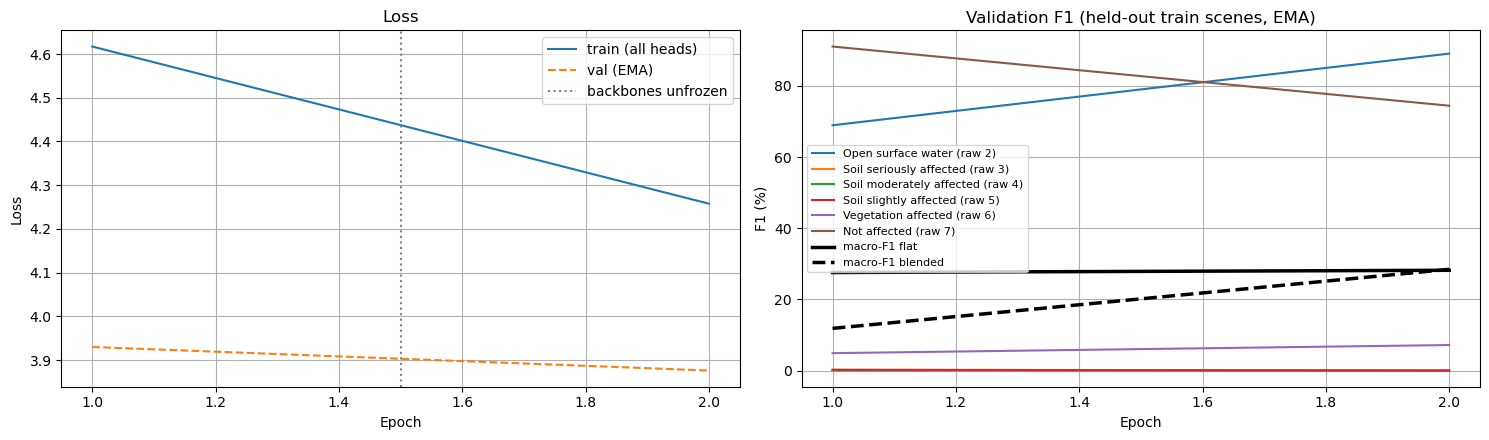

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
ep = np.arange(1, len(history["train_loss"]) + 1)
axes[0].plot(ep, history["train_loss"], label="train (all heads)")
axes[0].plot(ep, history["val_loss"], label="val (EMA)", linestyle="--")
axes[0].axvline(FREEZE_EPOCHS + 0.5, color="gray", linestyle=":", label="backbones unfrozen")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].set_title("Loss"); axes[0].legend(); axes[0].grid(True)
val_f1 = np.array(history["val_f1"])
for k in range(NUM_CLASSES):
    axes[1].plot(ep, 100 * val_f1[:, k], label=CLASS_NAMES[k])
axes[1].plot(ep, 100 * np.array(history["val_macro_f1"]), color="black", linewidth=2.5, label="macro-F1 flat")
axes[1].plot(ep, 100 * np.array(history["val_macro_f1_blend"]), color="black", linewidth=2.5,
             linestyle="--", label="macro-F1 blended")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("F1 (%)"); axes[1].set_title("Validation F1 (held-out train scenes, EMA)")
axes[1].legend(fontsize=8); axes[1].grid(True)
plt.tight_layout()
plt.show()

## 9. Ablation: what do terrain and radar contribute?

The same trained network is evaluated on the validation patches three ways: with everything, with the **terrain channels zeroed**, and with **Sentinel-1 zeroed**. These are inference-time ablations: the network never saw zeros in those channels during training, so the drop is an upper bound on each input's importance. Report it that way. For a strict ablation, retrain with `USE_DEM = False`.

In [ ]:
best = PTUPerNet().to(device)
best.load_state_dict(torch.load(BEST_PATH, map_location=device, weights_only=False)["model"])
best.eval()

ablation = {}
for label, kw in [("full model", {}), ("terrain zeroed", {"drop_dem": True}), ("Sentinel-1 zeroed", {"drop_s1": True})]:
    if label == "terrain zeroed" and not USE_DEM:
        continue
    _, cm_m, cm_b = evaluate_patches(best, val_loader, **kw)
    ablation[label] = {"macro_f1_flat": macro_f1(cm_m), "macro_f1_blend": macro_f1(cm_b),
                       "f1_blend": prf(cm_b)[2].tolist()}

short = ["Water", "Soil serious", "Soil moderate", "Soil slight", "Vegetation", "Not affected"]
print(f"{'Setting':<20}{'flat':>8}{'blend':>8}  " + "".join(f"{s:>15}" for s in short))
for label, r in ablation.items():
    print(f"{label:<20}{100 * r['macro_f1_flat']:>8.2f}{100 * r['macro_f1_blend']:>8.2f}  "
          + "".join(f"{100 * v:>15.2f}" for v in r["f1_blend"]))

Setting                 flat   blend            Water   Soil serious  Soil moderate    Soil slight     Vegetation   Not affected
full model             28.18   28.45            89.08           0.00           0.00           0.00           7.16          74.44
terrain zeroed         28.85   28.40            87.87           0.00           0.00           0.00           6.93          75.60
Sentinel-1 zeroed      29.24   27.98            93.83           0.00           0.00           0.00           7.73          66.33


## 10. Full-scene inference, head blending and calibration

Same protocol as notebook 11:

- 640×640 windows predict 512×512 centres, so there are no seams;
- D4 test-time augmentation (all 8 flips/rotations);
- the head-blend weight α and a per-class logit bias are fitted **only on the held-out training scenes**.

In [ ]:
def tile_starts(length: int, tile: int):
    starts = list(range(0, max(length - tile, 0) + 1, tile))
    if starts[-1] + tile < length:
        starts.append(length - tile)
    return starts


TTA_OPS = {"none": [(0, False)], "flip": [(0, False), (0, True)],
           "d4": [(k, f) for f in (False, True) for k in range(4)]}[TTA]


def _apply(x, k, flip):
    if flip:
        x = x.flip(-1)
    return torch.rot90(x, k, dims=(-2, -1)) if k else x


def _invert(x, k, flip):
    if k:
        x = torch.rot90(x, -k, dims=(-2, -1))
    return x.flip(-1) if flip else x


@torch.no_grad()
def predict_window(net, b):
    p_main = p_h = 0.0
    for k, flip in TTA_OPS:
        with autocast():
            out = net({key: _apply(v, k, flip) for key, v in b.items()})
        pm, ph = compose_probs(out)
        p_main = p_main + _invert(pm, k, flip)
        p_h = p_h + _invert(ph, k, flip)
    return p_main / len(TTA_OPS), p_h / len(TTA_OPS)


@torch.no_grad()
def scene_probs(net, sc: Scene, max_tiles=None):
    net.eval()
    done = 0
    for r0 in tile_starts(sc.H, TILE):
        for c0 in tile_starts(sc.W, TILE):
            ra, rb = max(r0 - MARGIN, 0), min(r0 + TILE + MARGIN, sc.H)
            ca, cb = max(c0 - MARGIN, 0), min(c0 + TILE + MARGIN, sc.W)
            s2, s1, aux = make_inputs(*sc.read(ra, ca, rb - ra, cb - ca))
            pad = ((0, 0), (MARGIN - (r0 - ra), MARGIN - (rb - r0 - TILE)),
                   (MARGIN - (c0 - ca), MARGIN - (cb - c0 - TILE)))
            b = {k: torch.from_numpy(np.pad(v, pad, mode="reflect"))[None].to(device)
                 for k, v in (("s2", s2), ("s1", s1), ("aux", aux))}
            pm, ph = predict_window(net, b)
            crop = (slice(None), slice(MARGIN, MARGIN + TILE), slice(MARGIN, MARGIN + TILE))
            yield r0, c0, pm[0][crop].cpu().numpy(), ph[0][crop].cpu().numpy()
            done += 1
            if max_tiles and done >= max_tiles:
                return


def blend_logp(pm, ph, alpha):
    return np.log((1 - alpha) * pm + alpha * ph + 1e-8)


def fit_logit_bias(logp: np.ndarray, y: np.ndarray, rounds: int = 3):
    grid = np.arange(-3.0, 3.01, 0.25, dtype=np.float32)
    bias = np.zeros(NUM_CLASSES, dtype=np.float32)
    best_s = macro_f1(confusion(y, logp.argmax(1)))
    for _ in range(rounds):
        for k in range(NUM_CLASSES):
            for v in grid:
                trial = bias.copy()
                trial[k] = v
                s = macro_f1(confusion(y, (logp + trial).argmax(1)))
                if s > best_s + 1e-6:
                    best_s, bias = s, trial
    return bias, best_s


rng = np.random.default_rng(SEED)
cal_pm, cal_ph, cal_y = [], [], []
for sc in val_scenes:
    t0 = time.time()
    for r0, c0, pm, ph in scene_probs(best, sc, MAX_TILES):
        y = sc.gt[r0:r0 + TILE, c0:c0 + TILE]
        take = (y != IGNORE) & (rng.random(y.shape) < 0.05)
        cal_pm.append(pm[:, take].T); cal_ph.append(ph[:, take].T); cal_y.append(y[take])
    print(f"  {sc.name}: inference {(time.time() - t0) / 60:.1f} min")
cal_pm = np.concatenate(cal_pm).astype(np.float32)
cal_ph = np.concatenate(cal_ph).astype(np.float32)
cal_y = np.concatenate(cal_y)
print(f"Calibration sample: {len(cal_y):,} pixels")

alpha_scores = {a: macro_f1(confusion(cal_y, blend_logp(cal_pm, cal_ph, a).argmax(1)))
                for a in (0.0, 0.25, 0.5, 0.75, 1.0)}
ALPHA = max(alpha_scores, key=alpha_scores.get)
print("Held-out macro-F1 by head blend alpha (0 = flat head, 1 = hierarchical):",
      {a: round(100 * s, 2) for a, s in alpha_scores.items()}, "-> alpha =", ALPHA)
cal_logp = blend_logp(cal_pm, cal_ph, ALPHA)
logit_bias, cal_score = fit_logit_bias(cal_logp, cal_y)
print(f"Held-out macro-F1: blended {100 * alpha_scores[ALPHA]:.2f} -> + logit bias {100 * cal_score:.2f}")
print("Logit bias per class:", np.round(logit_bias, 2).tolist())
CAL_PATH.write_text(json.dumps({"alpha": ALPHA, "logit_bias": logit_bias.tolist(),
                                "alpha_scores": {str(a): s for a, s in alpha_scores.items()},
                                "class_names": CLASS_NAMES}, indent=2))
del cal_pm, cal_ph, cal_y, cal_logp

  BNPI_20230208: inference 0.1 min
  KNPI_20220310: inference 0.0 min
Calibration sample: 52,269 pixels
Held-out macro-F1 by head blend alpha (0 = flat head, 1 = hierarchical): {0.0: 22.26, 0.25: 29.05, 0.5: 29.71, 0.75: 24.48, 1.0: 6.07} -> alpha = 0.5
Held-out macro-F1: blended 29.71 -> + logit bias 36.95
Logit bias per class: [-0.25, 0.75, 0.75, 0.75, -0.25, 0.0]


## 11. Evaluation on the 9 test scenes

There are two rows: **raw** (flat head, plain argmax) and **calibrated** (blended heads + logit bias, both fitted on held-out *training* scenes). The comparison table includes notebook 10's calibrated test results. If notebook 11 has been run, its `outputs/trf_results.json` numbers are added automatically.

In [ ]:
test_scenes = all_test[:2] if QUICK_TEST else all_test

cm_raw = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)
cm_cal = np.zeros_like(cm_raw)
pred_maps, per_scene = {}, {}
for sc in test_scenes:
    t0 = time.time()
    pred_raw = np.full((sc.H, sc.W), IGNORE, dtype=np.uint8)
    pred_cal = np.full((sc.H, sc.W), IGNORE, dtype=np.uint8)
    for r0, c0, pm, ph in scene_probs(best, sc, MAX_TILES):
        pred_raw[r0:r0 + TILE, c0:c0 + TILE] = pm.argmax(0)
        lp = blend_logp(pm, ph, ALPHA) + logit_bias[:, None, None]
        pred_cal[r0:r0 + TILE, c0:c0 + TILE] = lp.argmax(0)
    cm_raw += confusion(sc.gt, pred_raw)
    cm_scene = confusion(sc.gt, pred_cal)
    cm_cal += cm_scene
    pred_maps[sc.name] = pred_cal
    per_scene[sc.name] = {"macro_f1": macro_f1(cm_scene), "f1": prf(cm_scene)[2].tolist()}
    print(f"  {sc.name}: {(time.time() - t0) / 60:.1f} min | scene macro-F1 (calibrated) {100 * macro_f1(cm_scene):.2f}")

res_raw = report(cm_raw, "TEST SET - PT-UPerNet, flat head, raw argmax")
res_cal = report(cm_cal, f"TEST SET - PT-UPerNet, blended heads (alpha={ALPHA}) + logit bias")

columns = {"NB10": ([98.62, 71.04, 60.20, 63.54, 67.22, 98.56], 76.53, 81.53)}
trf_path = Path("outputs/trf_results.json")
if trf_path.exists():
    trf = json.loads(trf_path.read_text())
    if not trf.get("quick_test"):
        tc = trf["test_calibrated"]
        columns["NB11 TRF"] = ([100 * v for v in tc["f1"]], 100 * tc["macro_f1_all"], 100 * tc["weighted_water"][2])
columns["NB12 raw"] = ([100 * v for v in res_raw["f1"]], 100 * res_raw["macro_f1_all"], 100 * res_raw["weighted_water"][2])
columns["NB12 cal"] = ([100 * v for v in res_cal["f1"]], 100 * res_cal["macro_f1_all"], 100 * res_cal["weighted_water"][2])

print("\nPer-class F1 (%) on the test set")
print(f"{'Class':<36}" + "".join(f"{c:>11}" for c in columns))
for k in range(NUM_CLASSES):
    print(f"{CLASS_NAMES[k]:<36}" + "".join(f"{v[0][k]:>11.2f}" for v in columns.values()))
print(f"{'MACRO-F1 (6 classes)':<36}" + "".join(f"{v[1]:>11.2f}" for v in columns.values()))
print(f"{'Pixel-weighted F1, raw 2-6':<36}" + "".join(f"{v[2]:>11.2f}" for v in columns.values()))
print("Paper Table 1 best (RUPNet), pixel-weighted F1 raw 2-6: 81.19")

RESULTS_PATH.write_text(json.dumps({
    "model": "PT-UPerNet (notebook 12)", "quick_test": QUICK_TEST, "pretrained": PRETRAINED, "dem": USE_DEM,
    "alpha": ALPHA, "logit_bias": logit_bias.tolist(), "test_raw": res_raw, "test_calibrated": res_cal,
    "per_scene": per_scene, "val_ablation": ablation, "best_val_macro_f1": best_score,
    "confusion_calibrated": cm_cal.tolist(), "config": {**run_cfg, "tta": TTA, "tile": TILE, "margin": MARGIN},
}, indent=2))
print(f"\nSaved all numbers -> {RESULTS_PATH}")

  BNPI_20220208: 0.0 min | scene macro-F1 (calibrated) 27.05
  BNPI_20220325: 0.1 min | scene macro-F1 (calibrated) 21.23

TEST SET - PT-UPerNet, flat head, raw argmax
Cls Name                                   Pr (%)   Rc (%)   F1 (%)          Pixels
--------------------------------------------------------------------------------------
0   Open surface water (raw 2)               0.13   100.00     0.26             332
1   Soil seriously affected (raw 3)          0.00     0.00     0.00              28
2   Soil moderately affected (raw 4)         0.00     0.00     0.00             293
3   Soil slightly affected (raw 5)           0.00     0.00     0.00          30,068
4   Vegetation affected (raw 6)              0.36     7.14     0.69             392
5   Not affected (raw 7)                    97.63    75.68    85.27       1,017,463
--------------------------------------------------------------------------------------
    MACRO-F1, all 6 classes                                   14.37
  

## 12. Confusion matrix

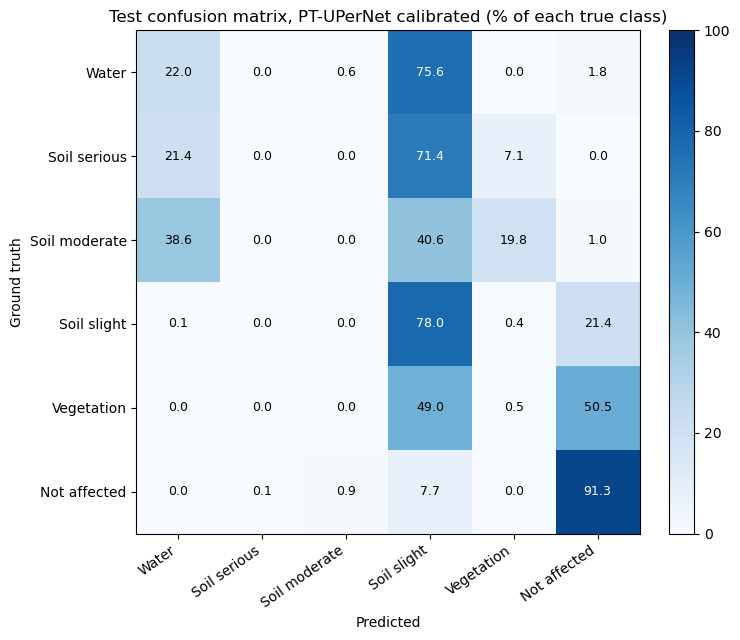

In [ ]:
cm_pct = 100 * cm_cal / np.maximum(cm_cal.sum(1, keepdims=True), 1)
fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(cm_pct, cmap="Blues", vmin=0, vmax=100)
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(short, rotation=35, ha="right")
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(short)
ax.set_xlabel("Predicted"); ax.set_ylabel("Ground truth")
ax.set_title("Test confusion matrix, PT-UPerNet calibrated (% of each true class)")
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(j, i, f"{cm_pct[i, j]:.1f}", ha="center", va="center",
                color="white" if cm_pct[i, j] > 55 else "black", fontsize=9)
fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

## 13. Prediction maps

For up to three test scenes, the 512×512 window richest in affected soil is shown four ways: true colour, the 1.5 km TPI terrain feature (blue = depression), the ground truth, and the calibrated prediction.

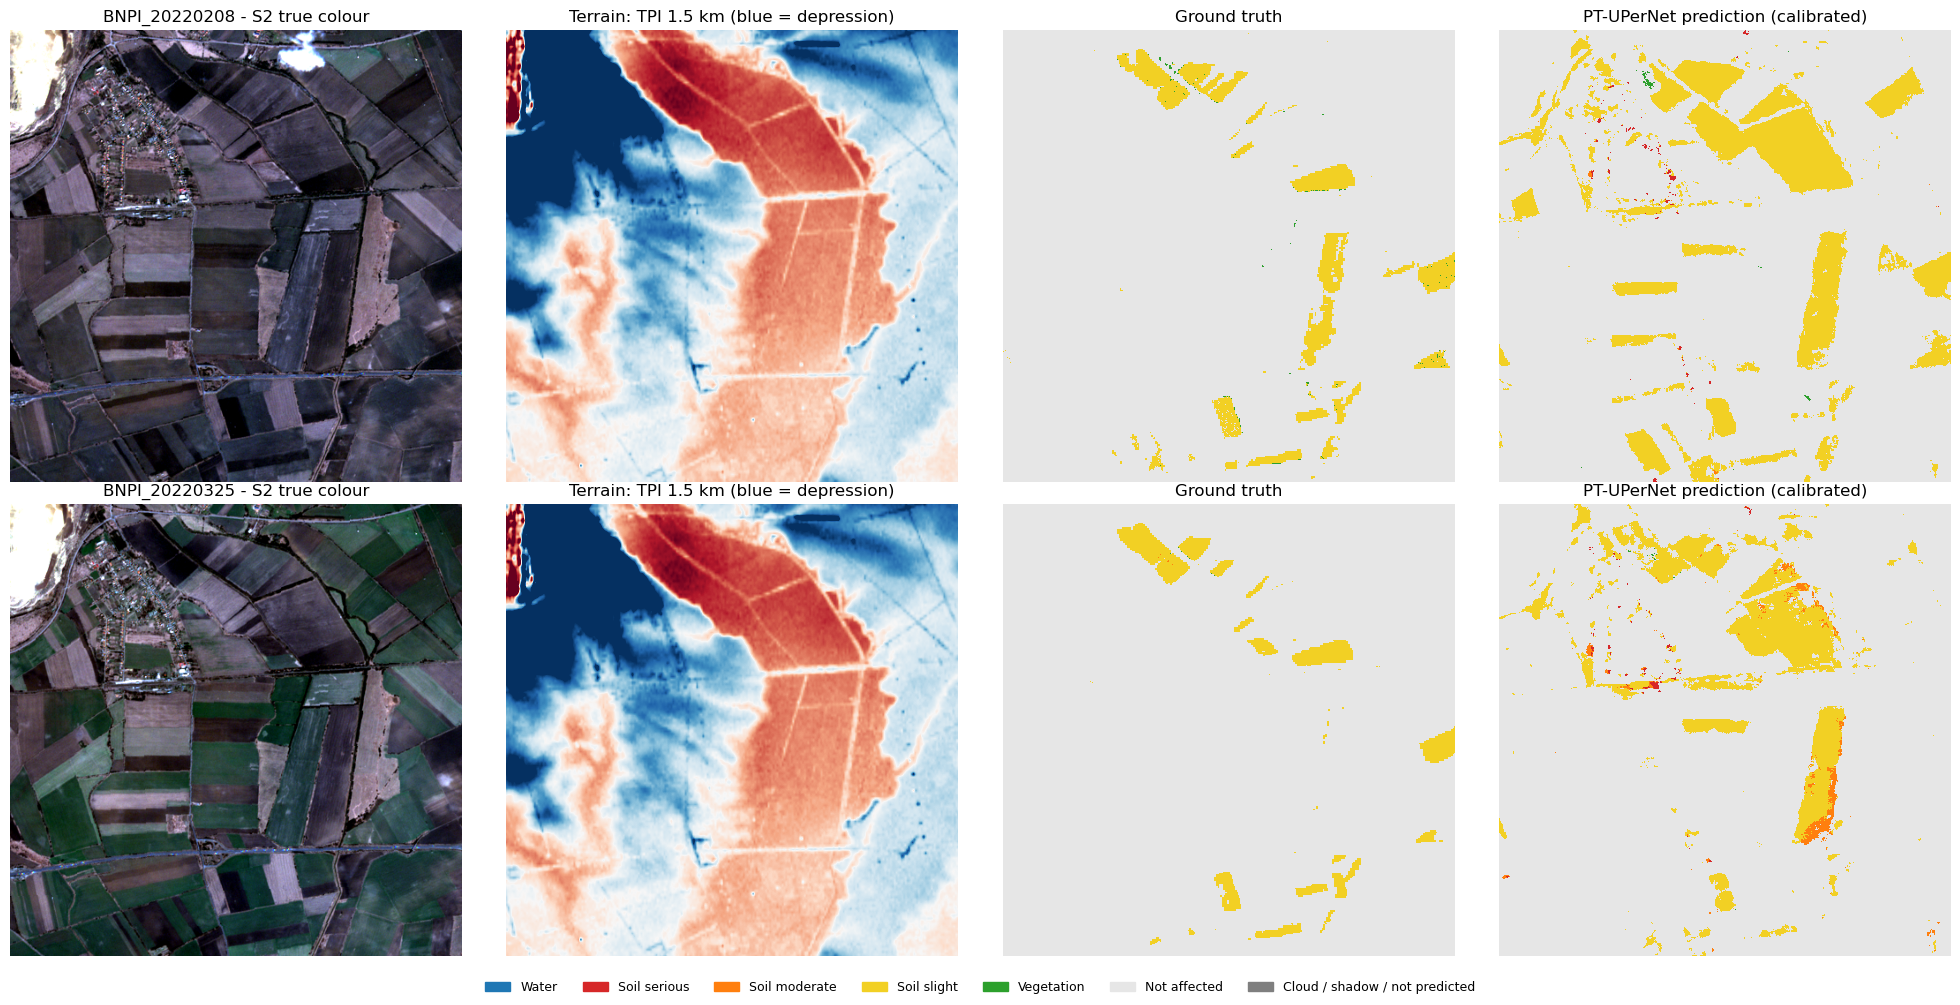

In [ ]:
PALETTE = ["#1f77b4", "#d62728", "#ff7f0e", "#f2d024", "#2ca02c", "#e6e6e6", "#7f7f7f"]
cmap = ListedColormap(PALETTE)


def to_display(label_map: np.ndarray) -> np.ndarray:
    return np.where(label_map == IGNORE, NUM_CLASSES, label_map)


def stretch_rgb(rgb: np.ndarray) -> np.ndarray:
    out = np.empty_like(rgb, dtype=np.float32)
    for k in range(3):
        lo, hi = np.percentile(rgb[..., k], [2, 98])
        out[..., k] = np.clip((rgb[..., k] - lo) / (hi - lo + 1e-8), 0, 1)
    return out


shown = [sc for sc in test_scenes if sc.name in pred_maps][:3]
fig, axes = plt.subplots(len(shown), 4, figsize=(20, 5 * len(shown)), squeeze=False)
for row, sc in enumerate(shown):
    pred = pred_maps[sc.name]
    block = 256
    soil = ((sc.gt >= 1) & (sc.gt <= 3)) & (pred != IGNORE)
    hb, wb = sc.H // block, sc.W // block
    counts = soil[:hb * block, :wb * block].reshape(hb, block, wb, block).sum((1, 3))
    bi, bj = np.unravel_index(counts.argmax(), counts.shape)
    r0 = int(np.clip(bi * block - 128, 0, sc.H - 512))
    c0 = int(np.clip(bj * block - 128, 0, sc.W - 512))
    s2, _, dem = sc.read(r0, c0, 512, 512)
    axes[row, 0].imshow(stretch_rgb(np.stack([s2[3], s2[2], s2[1]], -1).astype(np.float32)))
    axes[row, 0].set_title(f"{sc.name} - S2 true colour")
    if dem is not None:
        axes[row, 1].imshow(dem[4].astype(np.float32), cmap="RdBu", vmin=-3, vmax=3)
        axes[row, 1].set_title("Terrain: TPI 1.5 km (blue = depression)")
    else:
        axes[row, 1].set_title("no terrain (USE_DEM = False)")
    axes[row, 2].imshow(to_display(sc.gt[r0:r0 + 512, c0:c0 + 512]), cmap=cmap, vmin=0, vmax=NUM_CLASSES,
                        interpolation="nearest")
    axes[row, 2].set_title("Ground truth")
    axes[row, 3].imshow(to_display(pred[r0:r0 + 512, c0:c0 + 512]), cmap=cmap, vmin=0, vmax=NUM_CLASSES,
                        interpolation="nearest")
    axes[row, 3].set_title("PT-UPerNet prediction (calibrated)")
    for a in axes[row]:
        a.axis("off")
handles = [plt.Rectangle((0, 0), 1, 1, color=PALETTE[k]) for k in range(NUM_CLASSES + 1)]
fig.legend(handles, short + ["Cloud / shadow / not predicted"], loc="lower center", ncol=7, fontsize=9, frameon=False)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

## 14. Summary: fill in after running

| | Notebook 10 (calibrated) | Notebook 11 TRF | Notebook 12 PT-UPerNet |
|---|---|---|---|
| Water F1 | 98.62 | | |
| Soil seriously affected F1 | 71.04 | | |
| Soil moderately affected F1 | 60.20 | | |
| Soil slightly affected F1 | 63.54 | | |
| Vegetation affected F1 | 67.22 | | |
| Not affected F1 | 98.56 | | |
| Macro-F1 (6 classes) | 76.53 | | |
| Pixel-weighted F1, raw 2–6 (paper Table 1: 81.19) | 81.53 | | |

**Ablation (§9, validation):** full ___ / terrain zeroed ___ / Sentinel-1 zeroed ___

**Settings to report:** pre-trained on/off, DEM on/off, TTA mode, blend α, GPU and wall-clock time. All of these are saved in `outputs/ptuper_results.json`.

**Natural next step:** notebooks 11 and 12 bet on different information (time vs. pre-training + terrain), so their errors should differ. Averaging their calibrated probabilities per pixel is the most likely way to gain a few more F1 points on the hard classes.